In [35]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

# --- SETTING ---
MODEL_DIR = "ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model"
LABEL_MAP_PATH = "mscoco_label_map.pbtxt"

# --- LOAD LABEL MAP COCO ---
labels = {}
with open(LABEL_MAP_PATH, "r") as f:
    items = f.read().split("item {")
    for item in items[1:]:
        try:
            name = item.split("display_name: \"")[1].split("\"")[0]
        except:
            name = item.split("name: '")[1].split("'")[0]
        idx = int(item.split("id: ")[1].split("\n")[0])
        labels[idx] = name

# --- KONVERSI KE TFLITE ---
print("Konversi model ke TensorFlow Lite...")
converter = tf.lite.TFLiteConverter.from_saved_model(MODEL_DIR)

# Aktifkan quantization jika ingin model lebih kecil
# converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
with open("mobilenet.tflite", "wb") as f:
    f.write(tflite_model)
print("TFLite model berhasil disimpan: mobilenet.tflite")


Konversi model ke TensorFlow Lite...


W0000 00:00:1748510709.537353  242553 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1748510709.537730  242553 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2025-05-29 17:25:09.539124: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model
2025-05-29 17:25:09.573992: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2025-05-29 17:25:09.574005: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model
2025-05-29 17:25:09.798500: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2025-05-29 17:25:10.307950: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model
2025-05-29 17:25:10.593067: I tensorflow/cc/saved_model/loader.cc:471] Save

TFLite model berhasil disimpan: mobilenet.tflite


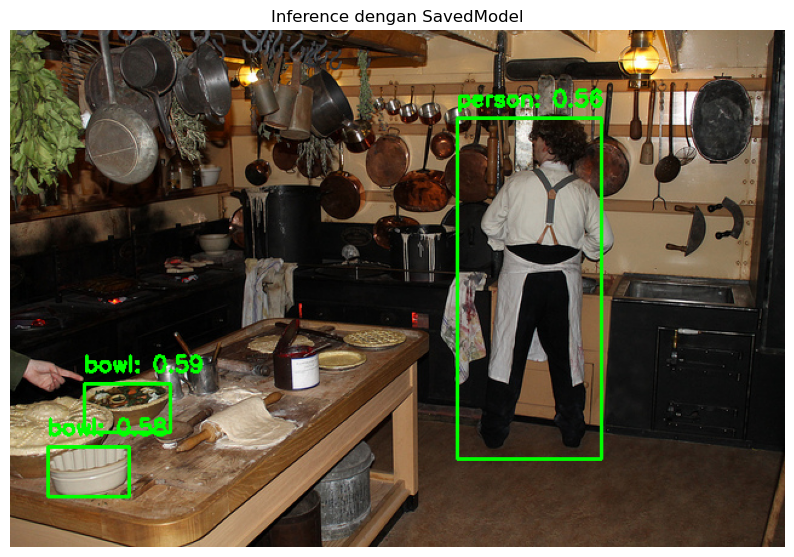

In [36]:
IMG_PATH = "human1.jpg"  # ganti ke nama file gambar di foldermu

# --- INFERENCE PAKAI SAVEDMODEL ---
detect_fn = tf.saved_model.load(MODEL_DIR)
img = cv2.imread(IMG_PATH)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
input_tensor = tf.cast(tf.convert_to_tensor([img_rgb]), dtype=tf.uint8)
detections = detect_fn(input_tensor)
boxes = detections['detection_boxes'][0].numpy()
scores = detections['detection_scores'][0].numpy()
classes = detections['detection_classes'][0].numpy().astype(int)

H, W = img.shape[:2]
for i in range(min(20, boxes.shape[0])):
    if scores[i] >= 0.50:
        ymin, xmin, ymax, xmax = boxes[i]
        (left, right, top, bottom) = (int(xmin * W), int(xmax * W), int(ymin * H), int(ymax * H))
        cv2.rectangle(img_rgb, (left, top), (right, bottom), (0,255,0), 2)
        label = labels.get(classes[i], str(classes[i]))
        cv2.putText(img_rgb, f"{label}: {scores[i]:.2f}", (left, top-10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

plt.figure(figsize=(10,10))
plt.imshow(img_rgb)
plt.axis('off')
plt.title("Inference dengan SavedModel")
plt.show()

Testing model

Total deteksi final: 6
Deteksi 1: ???, score=0.73, box=(381,75,494,342)
Deteksi 2: toilet, score=0.68, box=(0,152,193,294)
Deteksi 3: remote, score=0.68, box=(0,235,330,427)
Deteksi 4: bowl, score=0.55, box=(136,257,158,304)
Deteksi 5: ???, score=0.51, box=(343,64,358,88)
Deteksi 6: ???, score=0.50, box=(391,68,471,189)


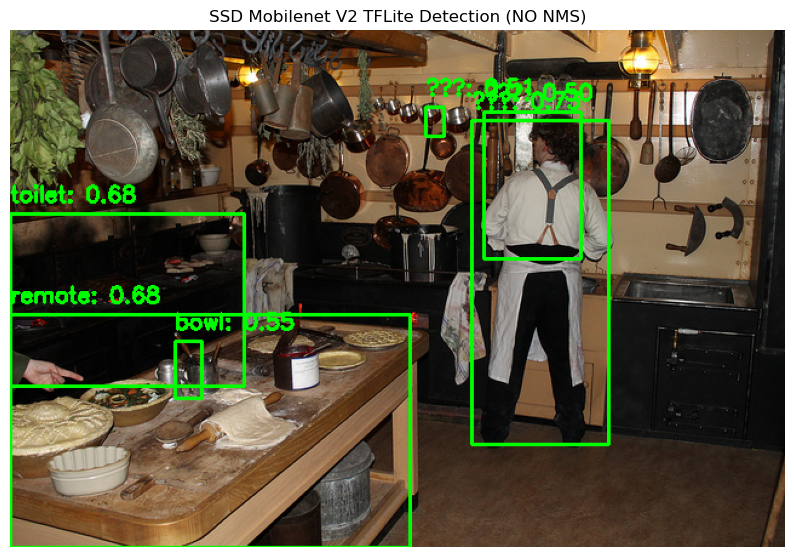

In [38]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

IMG_PATH = "human1.jpg"

# --- LOAD LABEL MAP ---
with open("labels.txt", "r") as f:
    labels = [line.strip() for line in f.readlines()]

# --- LOAD MODEL TFLITE ---
interpreter = tf.lite.Interpreter(model_path="detect.tflite")
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

img = cv2.imread(IMG_PATH)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
H, W = img.shape[:2]
ih, iw = input_details[0]['shape'][1], input_details[0]['shape'][2]

# --- PREPROCESS ---
input_data = cv2.resize(img_rgb, (iw, ih))
input_data = np.expand_dims(input_data, axis=0).astype(np.uint8)

interpreter.set_tensor(input_details[0]['index'], input_data)
interpreter.invoke()

# --- PARSE OUTPUT SSD Mobilenet V2 COCO ---
raw_boxes = interpreter.get_tensor(output_details[0]['index'])[0]   # shape: (N, 4)
raw_classes = interpreter.get_tensor(output_details[1]['index'])[0] # shape: (N,)
raw_scores = interpreter.get_tensor(output_details[2]['index'])[0]  # shape: (N,)
if len(output_details) > 3:
    num_detections = int(interpreter.get_tensor(output_details[3]['index'])[0])
else:
    num_detections = len(raw_scores)

dets = []
for i in range(num_detections):
    score = raw_scores[i]
    class_id = int(raw_classes[i])
    if score >= 0.5:
        ymin, xmin, ymax, xmax = raw_boxes[i]
        ymin = np.clip(ymin, 0, 1)
        xmin = np.clip(xmin, 0, 1)
        ymax = np.clip(ymax, 0, 1)
        xmax = np.clip(xmax, 0, 1)
        left   = int(xmin * W)
        right  = int(xmax * W)
        top    = int(ymin * H)
        bottom = int(ymax * H)
        dets.append([left, top, right, bottom, score, class_id])

# --- TANPA NMS ---
final_dets = dets

img_det = img_rgb.copy()
for box in final_dets:
    left, top, right, bottom, score, class_id = box
    label = labels[int(class_id)] if int(class_id) < len(labels) else str(int(class_id))
    cv2.rectangle(img_det, (int(left), int(top)), (int(right), int(bottom)), (0,255,0), 2)
    cv2.putText(
        img_det, f"{label}: {score:.2f}", (int(left), int(top)-10),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2
    )

print(f"Total deteksi final: {len(final_dets)}")
for i, box in enumerate(final_dets):
    left, top, right, bottom, score, class_id = box
    label = labels[int(class_id)] if int(class_id) < len(labels) else str(int(class_id))
    print(f"Deteksi {i+1}: {label}, score={score:.2f}, box=({left},{top},{right},{bottom})")

plt.figure(figsize=(10,10))
plt.imshow(img_det)
plt.axis('off')
plt.title("SSD Mobilenet V2 TFLite Detection (NO NMS)")
plt.show()